# **Proyecto: Pre-despacho y Despacho Economico de 20 Generadores mediante Algoritmos Geneticos**

## 1. Librerias y Datos del Sistema de 20 Generadores

En este primer bloque se importan las librerías necesarias y se cargan los parámetros técnicos y económicos de las 20 unidades generadoras distribuidas en los 3 nodos del sistema eléctrico ($P_{\min}$, $P_{\max}$, coeficientes $\alpha, \beta, \gamma$, costo de arranque $S_i$ y estado inicial en $t=0$). También se definen los límites máximos de potencia que puede entregar cada nodo ($1500\text{ MW}$ en el Nodo 1, $1200\text{ MW}$ en el Nodo 2 y $700\text{ MW}$ en el Nodo 3) y la curva de demanda diaria dividida en 3 bloques de 8 horas cada uno: Valle ($1600\text{ MW}$), Medio ($2600\text{ MW}$) y Pico ($3200\text{ MW}$).

In [2]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(25)
np.random.seed(25)

# Datos de las 20 unidades generadoras
# u_ini indica si la unidad estaba encendida (1) o apagada (0) antes del bloque 1
generadores = [
    {"id": "G1",  "nodo": 1, "p_min": 100.0, "p_max": 450.0, "alfa": 450.0, "beta": 15.2, "gamma": 0.0035, "s_arr": 3000.0, "u_ini": 1},
    {"id": "G2",  "nodo": 1, "p_min": 100.0, "p_max": 450.0, "alfa": 420.0, "beta": 15.5, "gamma": 0.0038, "s_arr": 2800.0, "u_ini": 1},
    {"id": "G3",  "nodo": 1, "p_min": 80.0,  "p_max": 350.0, "alfa": 380.0, "beta": 16.0, "gamma": 0.0042, "s_arr": 2400.0, "u_ini": 1},
    {"id": "G4",  "nodo": 1, "p_min": 80.0,  "p_max": 300.0, "alfa": 350.0, "beta": 16.8, "gamma": 0.0045, "s_arr": 2200.0, "u_ini": 1},
    {"id": "G5",  "nodo": 1, "p_min": 60.0,  "p_max": 250.0, "alfa": 300.0, "beta": 17.5, "gamma": 0.0050, "s_arr": 1800.0, "u_ini": 0},
    {"id": "G6",  "nodo": 1, "p_min": 50.0,  "p_max": 200.0, "alfa": 250.0, "beta": 18.2, "gamma": 0.0060, "s_arr": 1500.0, "u_ini": 0},
    {"id": "G7",  "nodo": 1, "p_min": 50.0,  "p_max": 200.0, "alfa": 240.0, "beta": 18.5, "gamma": 0.0062, "s_arr": 1400.0, "u_ini": 0},
    {"id": "G8",  "nodo": 2, "p_min": 80.0,  "p_max": 350.0, "alfa": 360.0, "beta": 19.0, "gamma": 0.0055, "s_arr": 2000.0, "u_ini": 0},
    {"id": "G9",  "nodo": 2, "p_min": 80.0,  "p_max": 300.0, "alfa": 340.0, "beta": 19.5, "gamma": 0.0058, "s_arr": 1900.0, "u_ini": 0},
    {"id": "G10", "nodo": 2, "p_min": 60.0,  "p_max": 250.0, "alfa": 280.0, "beta": 20.0, "gamma": 0.0065, "s_arr": 1600.0, "u_ini": 0},
    {"id": "G11", "nodo": 2, "p_min": 50.0,  "p_max": 200.0, "alfa": 220.0, "beta": 21.0, "gamma": 0.0070, "s_arr": 1200.0, "u_ini": 0},
    {"id": "G12", "nodo": 2, "p_min": 40.0,  "p_max": 180.0, "alfa": 200.0, "beta": 21.8, "gamma": 0.0075, "s_arr": 1100.0, "u_ini": 0},
    {"id": "G13", "nodo": 2, "p_min": 30.0,  "p_max": 150.0, "alfa": 180.0, "beta": 22.5, "gamma": 0.0080, "s_arr": 900.0,  "u_ini": 0},
    {"id": "G14", "nodo": 2, "p_min": 30.0,  "p_max": 120.0, "alfa": 150.0, "beta": 23.2, "gamma": 0.0085, "s_arr": 800.0,  "u_ini": 0},
    {"id": "G15", "nodo": 3, "p_min": 40.0,  "p_max": 160.0, "alfa": 160.0, "beta": 24.0, "gamma": 0.0090, "s_arr": 750.0,  "u_ini": 0},
    {"id": "G16", "nodo": 3, "p_min": 30.0,  "p_max": 140.0, "alfa": 140.0, "beta": 25.5, "gamma": 0.0095, "s_arr": 600.0,  "u_ini": 0},
    {"id": "G17", "nodo": 3, "p_min": 25.0,  "p_max": 120.0, "alfa": 120.0, "beta": 26.8, "gamma": 0.0105, "s_arr": 500.0,  "u_ini": 0},
    {"id": "G18", "nodo": 3, "p_min": 20.0,  "p_max": 100.0, "alfa": 100.0, "beta": 28.0, "gamma": 0.0115, "s_arr": 400.0,  "u_ini": 0},
    {"id": "G19", "nodo": 3, "p_min": 20.0,  "p_max": 80.0,  "alfa": 90.0,  "beta": 29.5, "gamma": 0.0125, "s_arr": 350.0,  "u_ini": 0},
    {"id": "G20", "nodo": 3, "p_min": 15.0,  "p_max": 60.0,  "alfa": 80.0,  "beta": 31.0, "gamma": 0.0135, "s_arr": 300.0,  "u_ini": 0}
]

N_GEN = len(generadores)
LIMITES_NODOS = {1: 1500.0, 2: 1200.0, 3: 700.0}
DEMANDAS_BLOQUES = [1600.0, 2600.0, 3200.0]
NOMBRES_BLOQUES = ["Bloque 1 (Valle - 1600 MW)", "Bloque 2 (Medio - 2600 MW)", "Bloque 3 (Pico - 3200 MW)"]
HORAS_POR_BLOQUE = 8.0

## 2. Solucion del Despacho Economico mediante el Criterio Lambda

Este bloque implementa el cálculo del despacho económico continuo para las unidades que se encuentran encendidas ($U_{i,t} = 1$) en un bloque horario determinado, aplicando la ecuación del costo incremental igual $P_i = (\lambda - \beta_i) / (2\gamma_i)$ acotada entre $P_{\min}$ y $P_{\max}$. Cuando están activas las restricciones por nodo, la función verifica si la suma de potencia de las máquinas en algún nodo supera el límite máximo permitido ($P_{\text{nodo}, k}^{\max}$); de ser así, ajusta el valor de $\lambda$ local de ese nodo para que entregue exactamente su potencia máxima sin desbordarse y reparte el resto de la demanda entre los demás nodos disponibles.


In [3]:
# Calcula la potencia de un grupo de generadores encendidos buscando el valor de lambda
def calcular_lambda_grupo(indices_activos, demanda_objetivo):
    if len(indices_activos) == 0 or demanda_objetivo <= 0:
        return {}, 0.0

    p_min_total = sum(generadores[i]["p_min"] for i in indices_activos)
    p_max_total = sum(generadores[i]["p_max"] for i in indices_activos)

    # Si la demanda es menor al minimo tecnico del grupo, quedan en Pmin
    if demanda_objetivo <= p_min_total:
        potencias = {i: generadores[i]["p_min"] for i in indices_activos}
        lam = min(generadores[i]["beta"] + 2 * generadores[i]["gamma"] * generadores[i]["p_min"] for i in indices_activos)
        return potencias, lam

    # Si la demanda supera el maximo del grupo, entregan Pmax
    if demanda_objetivo >= p_max_total:
        potencias = {i: generadores[i]["p_max"] for i in indices_activos}
        lam = max(generadores[i]["beta"] + 2 * generadores[i]["gamma"] * generadores[i]["p_max"] for i in indices_activos)
        return potencias, lam

    # Busqueda por biseccion del costo incremental lambda
    lam_inf = 10.0
    lam_sup = 50.0

    for _ in range(30):
        lam_med = 0.5 * (lam_inf + lam_sup)
        suma_p = 0.0
        for i in indices_activos:
            g = generadores[i]
            p_i = (lam_med - g["beta"]) / (2.0 * g["gamma"])
            if p_i < g["p_min"]:
                p_i = g["p_min"]
            elif p_i > g["p_max"]:
                p_i = g["p_max"]
            suma_p += p_i

        if suma_p < demanda_objetivo:
            lam_inf = lam_med
        else:
            lam_sup = lam_med

    lam_final = 0.5 * (lam_inf + lam_sup)
    potencias = {}
    for i in indices_activos:
        g = generadores[i]
        p_i = (lam_final - g["beta"]) / (2.0 * g["gamma"])
        p_i = max(g["p_min"], min(g["p_max"], p_i))
        potencias[i] = p_i

    return potencias, lam_final


# Despacho economico del bloque respetando limites de potencia por nodo
def resolver_despacho_bloque(u_bloque, demanda_bloque, usar_limites_nodos=True):
    potencias_bloque = [0.0] * N_GEN
    lambdas_nodos = {1: 0.0, 2: 0.0, 3: 0.0}

    activos = [i for i in range(N_GEN) if u_bloque[i] == 1]
    if len(activos) == 0:
        return potencias_bloque, lambdas_nodos

    nodos_libres = [1, 2, 3]
    demanda_restante = demanda_bloque

    # Iteramos para detectar si algun nodo supera su capacidad maxima
    while len(nodos_libres) > 0:
        activos_libres = [i for i in activos if generadores[i]["nodo"] in nodos_libres]
        if len(activos_libres) == 0:
            break

        pot_temp, lam_temp = calcular_lambda_grupo(activos_libres, demanda_restante)

        nodo_congestionado = None
        if usar_limites_nodos:
            for k in nodos_libres:
                suma_nodo = sum(pot_temp[i] for i in activos_libres if generadores[i]["nodo"] == k)
                if suma_nodo > LIMITES_NODOS[k] + 1e-4:
                    nodo_congestionado = k
                    break

        if nodo_congestionado is not None:
            # Fijamos el nodo congestionado en su limite maximo permitido
            activos_nodo = [i for i in activos if generadores[i]["nodo"] == nodo_congestionado]
            pot_nodo, lam_nodo = calcular_lambda_grupo(activos_nodo, LIMITES_NODOS[nodo_congestionado])
            for i, val_p in pot_nodo.items():
                potencias_bloque[i] = val_p
            lambdas_nodos[nodo_congestionado] = lam_nodo
            demanda_restante -= sum(pot_nodo.values())
            nodos_libres.remove(nodo_congestionado)
        else:
            # Ningun nodo libre supera su limite
            for i, val_p in pot_temp.items():
                potencias_bloque[i] = val_p
            for k in nodos_libres:
                tiene_activos = any(generadores[i]["nodo"] == k for i in activos_libres)
                lambdas_nodos[k] = lam_temp if tiene_activos else 0.0
            break

    return potencias_bloque, lambdas_nodos

## 3. Funcion Objetivo de Costo Total y Calculo del Fitness

En este bloque se evalúa el cromosoma completo de $60$ bits ($20$ bits por cada uno de los $3$ bloques horarios). Para cada bloque se obtiene el despacho de potencia $P_{i,t}$, se calcula el costo de combustible multiplicado por las $8$ horas de duración del bloque y se suman los costos de arranque $S_i$ cuando una unidad pasa de estar apagada ($0$) a encendida ($1$). Si la combinación de unidades elegida no logra cubrir la demanda o si el mínimo técnico de un nodo excede la capacidad máxima nodal, se aplican las penalizaciones cuadráticas $K_P$ y $K_{\text{nodo}}$ antes de invertir el costo para obtener el valor de adaptación (fitness).


In [4]:
def evaluar_cromosoma_despacho(cromosoma, usar_limites_nodos=True):
    costo_combustible_total = 0.0
    costo_arranque_total = 0.0
    penalizacion_balance = 0.0
    penalizacion_nodos = 0.0

    K_P = 10000.0
    K_NODO = 10000.0

    # Estado previo al bloque 1
    u_anterior = [g["u_ini"] for g in generadores]

    detalle_bloques = []

    for t in range(3):
        inicio = t * N_GEN
        u_actual = cromosoma[inicio : inicio + N_GEN]
        demanda_t = DEMANDAS_BLOQUES[t]

        potencias_t, lambdas_t = resolver_despacho_bloque(u_actual, demanda_t, usar_limites_nodos)

        # 1. Costo de combustible y arranque en el bloque t
        costo_comb_bloque = 0.0
        costo_arr_bloque = 0.0

        for i in range(N_GEN):
            if u_actual[i] == 1:
                g = generadores[i]
                p_i = potencias_t[i]
                costo_hora = g["alfa"] + g["beta"] * p_i + g["gamma"] * (p_i ** 2)
                costo_comb_bloque += costo_hora * HORAS_POR_BLOQUE

                if u_anterior[i] == 0:
                    costo_arr_bloque += g["s_arr"]

        costo_combustible_total += costo_comb_bloque
        costo_arranque_total += costo_arr_bloque

        # 2. Verificacion de penalizaciones por balance de potencia y por nodos
        generacion_total_t = sum(potencias_t)
        error_demanda = abs(generacion_total_t - demanda_t)
        if error_demanda > 1e-2:
            penalizacion_balance += K_P * (error_demanda ** 2)

        potencia_por_nodo = {1: 0.0, 2: 0.0, 3: 0.0}
        for i in range(N_GEN):
            potencia_por_nodo[generadores[i]["nodo"]] += potencias_t[i]

        if usar_limites_nodos:
            for k in [1, 2, 3]:
                exceso = max(0.0, potencia_por_nodo[k] - LIMITES_NODOS[k])
                if exceso > 1e-2:
                    penalizacion_nodos += K_NODO * (exceso ** 2)

        detalle_bloques.append({
            "u": u_actual[:],
            "potencias": potencias_t[:],
            "pot_nodos": potencia_por_nodo,
            "lambdas": lambdas_t,
            "costo_comb": costo_comb_bloque,
            "costo_arr": costo_arr_bloque
        })

        u_anterior = u_actual[:]

    costo_real = costo_combustible_total + costo_arranque_total
    costo_evaluado = costo_real + penalizacion_balance + penalizacion_nodos

    # Escalamos por 10^6 para que el fitness quede en un rango comodo de visualizar
    fitness = 1e6 / (costo_evaluado + 1e-4)

    return fitness, costo_real, costo_evaluado, detalle_bloques

## 4. Operadores y Motor del Algoritmo Genetico (AGS1 y AGM5)

En este bloque se reutilizan los operadores desarrollados en las tareas anteriores: selección por ruleta, cruce (de dos puntos para preservar mejor los bloques horarios), mutación bit a bit, renormalización lineal con tope y paso, elitismo, sustitución parcial (Gap de $10\%$) y control de duplicados. La función `ejecutar_ag_uc()` permite correr tanto el Algoritmo Genético Simple (**AGS1**) como el Algoritmo Genético Modificado (**AGM5**) manteniendo exactamente el mismo número de evaluaciones de la función de adaptación.


In [5]:
def seleccion_ruleta_individuo(poblacion, aptitudes):
    suma_total = sum(aptitudes)
    if suma_total <= 0:
        return random.choice(poblacion)[:]
    r = random.uniform(0, suma_total)
    acumulado = 0.0
    for ind, apt in zip(poblacion, aptitudes):
        acumulado += apt
        if acumulado >= r:
            return ind[:]
    return poblacion[-1][:]

def cruce_dos_puntos(padre1, padre2, prob_cruce):
    if random.random() < prob_cruce:
        p1 = random.randint(1, len(padre1) - 2)
        p2 = random.randint(p1 + 1, len(padre1) - 1)
        hijo1 = padre1[:p1] + padre2[p1:p2] + padre1[p2:]
        hijo2 = padre2[:p1] + padre1[p1:p2] + padre2[p2:]
        return hijo1, hijo2
    return padre1[:], padre2[:]

def mutacion(cromosoma, prob_mutacion):
    for i in range(len(cromosoma)):
        if random.random() < prob_mutacion:
            cromosoma[i] = 1 - cromosoma[i]
    return cromosoma

def aplicar_renormalizacion_lineal(n, tope=100.0, paso=1.0):
    aptitudes_renorm = []
    for i in range(n):
        val = tope - (i * paso)
        aptitudes_renorm.append(val if val > 0 else 1e-4)
    return aptitudes_renorm

def ejecutar_ag_uc(
    modo="AGM5",
    n_pob=100,
    max_evaluaciones=6000,
    pc=0.85,
    pm=0.0167,
    gap=0.10,
    tope=100.0,
    paso=1.0,
    usar_limites_nodos=True
):
    long_cromosoma = N_GEN * 3
    es_agm5 = (modo == "AGM5")

    poblacion = []
    registro_unicos = set()

    # Inicializamos la poblacion con probabilidad 0.75 de encender unidades para facilitar factibilidad inicial
    while len(poblacion) < n_pob:
        crom = [1 if random.random() < 0.75 else 0 for _ in range(long_cromosoma)]
        t_crom = tuple(crom)
        if es_agm5:
            if t_crom not in registro_unicos:
                registro_unicos.add(t_crom)
                poblacion.append(crom)
        else:
            poblacion.append(crom)

    datos_pob = []
    for crom in poblacion:
        fit, c_real, c_eval, det = evaluar_cromosoma_despacho(crom, usar_limites_nodos)
        datos_pob.append({
            "crom": crom, "adap": fit, "costo_real": c_real, "costo_eval": c_eval, "detalle": det
        })

    n_reemplazo = max(1, int(round(n_pob * gap))) if es_agm5 else n_pob

    evaluaciones_actuales = 0
    eje_evaluaciones = [0]

    mejor_historico = max(datos_pob, key=lambda d: d["adap"]).copy()
    historial_mejor_costo = [mejor_historico["costo_eval"]]
    historial_max_adap = [mejor_historico["adap"]]

    while evaluaciones_actuales < max_evaluaciones:
        datos_pob.sort(key=lambda d: d["adap"], reverse=True)

        if datos_pob[0]["adap"] > mejor_historico["adap"]:
            mejor_historico = datos_pob[0].copy()

        cromosomas_ordenados = [d["crom"] for d in datos_pob]

        if es_agm5:
            aptitudes_seleccion = aplicar_renormalizacion_lineal(len(datos_pob), tope, paso)
        else:
            aptitudes_seleccion = [d["adap"] for d in datos_pob]

        hijos_necesarios = min(n_reemplazo, max_evaluaciones - evaluaciones_actuales)
        nuevos_hijos = []
        intentos_dup = 0

        while len(nuevos_hijos) < hijos_necesarios:
            padre1 = seleccion_ruleta_individuo(cromosomas_ordenados, aptitudes_seleccion)
            padre2 = seleccion_ruleta_individuo(cromosomas_ordenados, aptitudes_seleccion)

            hijo1, hijo2 = cruce_dos_puntos(padre1, padre2, pc)
            mutacion(hijo1, pm)
            mutacion(hijo2, pm)

            for h in (hijo1, hijo2):
                if len(nuevos_hijos) >= hijos_necesarios:
                    break

                if es_agm5:
                    t_h = tuple(h)
                    if t_h in registro_unicos:
                        intentos_dup += 1
                        if intentos_dup > 10:
                            bit_azar = random.randint(0, long_cromosoma - 1)
                            h[bit_azar] = 1 - h[bit_azar]
                            t_h = tuple(h)
                            if t_h in registro_unicos:
                                continue
                        else:
                            continue
                    registro_unicos.add(t_h)

                fit_h, c_real_h, c_eval_h, det_h = evaluar_cromosoma_despacho(h, usar_limites_nodos)
                evaluaciones_actuales += 1
                nuevos_hijos.append({
                    "crom": h, "adap": fit_h, "costo_real": c_real_h, "costo_eval": c_eval_h, "detalle": det_h
                })

        if es_agm5:
            sobrevivientes = datos_pob[: n_pob - len(nuevos_hijos)]
            eliminados = datos_pob[n_pob - len(nuevos_hijos) :]
            for d_elim in eliminados:
                registro_unicos.discard(tuple(d_elim["crom"]))
            datos_pob = sobrevivientes + nuevos_hijos
        else:
            datos_pob = nuevos_hijos

        mejor_gen = max(datos_pob, key=lambda d: d["adap"])
        if mejor_gen["adap"] > mejor_historico["adap"]:
            mejor_historico = mejor_gen.copy()

        eje_evaluaciones.append(evaluaciones_actuales)
        historial_mejor_costo.append(mejor_historico["costo_eval"])
        historial_max_adap.append(max(d["adap"] for d in datos_pob))

    return eje_evaluaciones, historial_mejor_costo, historial_max_adap, mejor_historico

## 5. Ejecucion, Tablas de Despacho por Bloques y Graficas Comparativas

En este último bloque se ejecuta la simulación comparando el rendimiento del **AGS1** frente al **AGM5** sobre el sistema con restricciones nodales, y adicionalmente se evalúa el caso sin límites en los nodos para cuantificar el sobrecosto producido por la congestión de la red. Finalmente, se imprimen las tablas con la programación horaria de las $20$ máquinas ($U_{i,t}$ y $P_{i,t}$), los costos incrementales $\lambda$ por nodo y las gráficas de evolución del costo y reparto de potencia por nodo.


Ejecutando optimizacion de Pre-despacho y Despacho Economico (20 Generadores)...

TABLA 1: PROGRAMACION OPTIMA DE LAS 20 UNIDADES ENCONTRADA POR AGM5 (CON LIMITES NODALES)

Gen   | Nodo | Pmin-Pmax   | Bloque 1 (1600 MW)   | Bloque 2 (2600 MW)   | Bloque 3 (3200 MW)  
-----------------------------------------------------------------------------------------------
G1    | 1    | 100-450     | U=1 |  450.0 MW      | U=1 |  450.0 MW      | U=1 |  450.0 MW     
G2    | 1    | 100-450     | U=1 |  450.0 MW      | U=1 |  450.0 MW      | U=1 |  450.0 MW     
G3    | 1    | 80-350      | U=1 |  350.0 MW      | U=1 |  350.0 MW      | U=1 |  350.0 MW     
G4    | 1    | 80-300      | U=1 |  250.0 MW      | U=1 |  250.0 MW      | U=1 |  250.0 MW     
G5    | 1    | 60-250      | U=0 |    0.0 MW      | U=0 |    0.0 MW      | U=0 |    0.0 MW     
G6    | 1    | 50-200      | U=0 |    0.0 MW      | U=0 |    0.0 MW      | U=0 |    0.0 MW     
G7    | 1    | 50-200      | U=0 |    0.0 MW      | U=0 |  

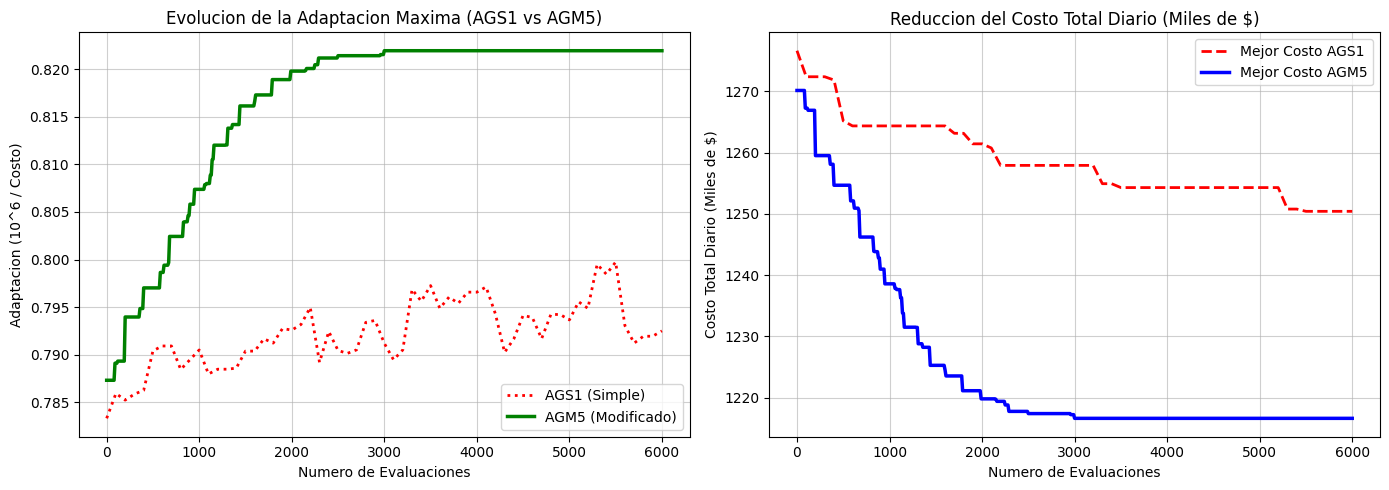

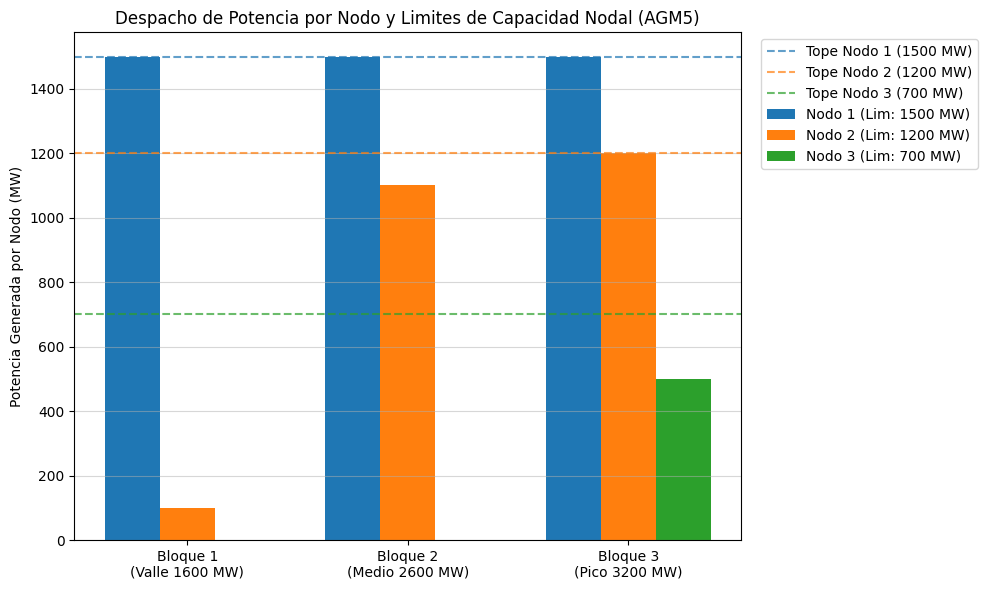

In [6]:
N_POB = 100
MAX_EVALS = 6000

print("Ejecutando optimizacion de Pre-despacho y Despacho Economico (20 Generadores)...")

# 1. Ejecucion con limites nodales: AGS1 vs AGM5
eje_ags1, costo_ags1, adap_ags1, mejor_ags1 = ejecutar_ag_uc(
    modo="AGS1", n_pob=N_POB, max_evaluaciones=MAX_EVALS, usar_limites_nodos=True
)

eje_agm5, costo_agm5, adap_agm5, mejor_agm5 = ejecutar_ag_uc(
    modo="AGM5", n_pob=N_POB, max_evaluaciones=MAX_EVALS, usar_limites_nodos=True
)

# 2. Ejecucion con AGM5 sin limites nodales (Red ideal sin congestion) para comparar lambda
_, _, _, mejor_sin_limites = ejecutar_ag_uc(
    modo="AGM5", n_pob=N_POB, max_evaluaciones=MAX_EVALS, usar_limites_nodos=False
)

# TABLA 1: Despacho detallado de las 20 unidades con AGM5 (Con limites por nodo)
print("\nTABLA 1: PROGRAMACION OPTIMA DE LAS 20 UNIDADES ENCONTRADA POR AGM5 (CON LIMITES NODALES)\n")
encabezado = f"{'Gen':<5} | {'Nodo':<4} | {'Pmin-Pmax':<11} | {'Bloque 1 (1600 MW)':<20} | {'Bloque 2 (2600 MW)':<20} | {'Bloque 3 (3200 MW)':<20}"
print(encabezado)
print("-" * len(encabezado))

det_opt = mejor_agm5["detalle"]
for i in range(N_GEN):
    g = generadores[i]
    rango_str = f"{int(g['p_min'])}-{int(g['p_max'])}"
    b1_str = f"U={det_opt[0]['u'][i]} | {det_opt[0]['potencias'][i]:>6.1f} MW"
    b2_str = f"U={det_opt[1]['u'][i]} | {det_opt[1]['potencias'][i]:>6.1f} MW"
    b3_str = f"U={det_opt[2]['u'][i]} | {det_opt[2]['potencias'][i]:>6.1f} MW"
    print(f"{g['id']:<5} | {g['nodo']:<4} | {rango_str:<11} | {b1_str:<20} | {b2_str:<20} | {b3_str:<20}")

print("-" * len(encabezado))

# TABLA 2: Resumen por Nodo y Costos Incrementales Lambda
print("\nTABLA 2: POTENCIA GENERADA Y COSTO INCREMENTAL LAMBDA POR NODO (AGM5)\n")
print(f"{'Bloque Horario':<28} | {'Nodo 1 (Max 1500 MW)':<24} | {'Nodo 2 (Max 1200 MW)':<24} | {'Nodo 3 (Max 700 MW)':<24}")
print("-" * 108)

for t in range(3):
    d_t = det_opt[t]
    n1_str = f"{d_t['pot_nodos'][1]:>6.1f} MW (L={d_t['lambdas'][1]:>5.2f})"
    n2_str = f"{d_t['pot_nodos'][2]:>6.1f} MW (L={d_t['lambdas'][2]:>5.2f})"
    n3_str = f"{d_t['pot_nodos'][3]:>6.1f} MW (L={d_t['lambdas'][3]:>5.2f})"
    print(f"{NOMBRES_BLOQUES[t]:<28} | {n1_str:<24} | {n2_str:<24} | {n3_str:<24}")
print("-" * 108)

# TABLA 3: Comparacion Economica Global
print("\nTABLA 3: RESUMEN ECONOMICO DIARIO (24 HORAS)\n")
print(f"{'Escenario Evaluado':<38} | {'Costo Combustible ($)':<22} | {'Costo Arranque ($)':<19} | {'Costo Total Diario ($)'}")
print("-" * 106)

for nombre_esc, res in [
    ("AGS1 (Con limites nodales)", mejor_ags1),
    ("AGM5 (Con limites nodales)", mejor_agm5),
    ("AGM5 (Sin limites nodales - Ideal)", mejor_sin_limites)
]:
    c_comb = sum(b["costo_comb"] for b in res["detalle"])
    c_arr = sum(b["costo_arr"] for b in res["detalle"])
    c_tot = res["costo_real"]
    print(f"{nombre_esc:<38} | {c_comb:<22,.2f} | {c_arr:<19,.2f} | {c_tot:,.2f}")
print("-" * 106)

# GRAFICA 1: Evolucion de la Adaptacion y Reduccion de Costos (AGS1 vs AGM5)
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

axs[0].plot(eje_ags1, adap_ags1, label="AGS1 (Simple)", color="red", linestyle=":", linewidth=2)
axs[0].plot(eje_agm5, adap_agm5, label="AGM5 (Modificado)", color="green", linewidth=2.5)
axs[0].set_title("Evolucion de la Adaptacion Maxima (AGS1 vs AGM5)")
axs[0].set_xlabel("Numero de Evaluaciones")
axs[0].set_ylabel("Adaptacion (10^6 / Costo)")
axs[0].grid(True, alpha=0.6)
axs[0].legend(loc="lower right")

axs[1].plot(eje_ags1, [c / 1000.0 for c in costo_ags1], label="Mejor Costo AGS1", color="red", linestyle="--", linewidth=2)
axs[1].plot(eje_agm5, [c / 1000.0 for c in costo_agm5], label="Mejor Costo AGM5", color="blue", linewidth=2.5)
axs[1].set_title("Reduccion del Costo Total Diario (Miles de $)")
axs[1].set_xlabel("Numero de Evaluaciones")
axs[1].set_ylabel("Costo Total Diario (Miles de $)")
axs[1].grid(True, alpha=0.6)
axs[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

# GRAFICA 2: Generacion por Nodo vs Limite Maximo en cada Bloque Horario
bloques_labels = ["Bloque 1\n(Valle 1600 MW)", "Bloque 2\n(Medio 2600 MW)", "Bloque 3\n(Pico 3200 MW)"]
x_pos = np.arange(len(bloques_labels))
ancho = 0.25

p_nodo1 = [det_opt[t]["pot_nodos"][1] for t in range(3)]
p_nodo2 = [det_opt[t]["pot_nodos"][2] for t in range(3)]
p_nodo3 = [det_opt[t]["pot_nodos"][3] for t in range(3)]

plt.figure(figsize=(10, 6))
plt.bar(x_pos - ancho, p_nodo1, width=ancho, label="Nodo 1 (Lim: 1500 MW)", color="#1f77b4")
plt.bar(x_pos,         p_nodo2, width=ancho, label="Nodo 2 (Lim: 1200 MW)", color="#ff7f0e")
plt.bar(x_pos + ancho, p_nodo3, width=ancho, label="Nodo 3 (Lim: 700 MW)",  color="#2ca02c")

# Lineas de limite por nodo
plt.axhline(1500, color="#1f77b4", linestyle="--", alpha=0.7, label="Tope Nodo 1 (1500 MW)")
plt.axhline(1200, color="#ff7f0e", linestyle="--", alpha=0.7, label="Tope Nodo 2 (1200 MW)")
plt.axhline(700,  color="#2ca02c", linestyle="--", alpha=0.7, label="Tope Nodo 3 (700 MW)")

plt.xticks(x_pos, bloques_labels)
plt.ylabel("Potencia Generada por Nodo (MW)")
plt.title("Despacho de Potencia por Nodo y Limites de Capacidad Nodal (AGM5)")
plt.grid(True, axis="y", alpha=0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()